In [21]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense,SimpleRNN,LSTM,Bidirectional
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

In [2]:
data=pd.read_csv('Airpassengers.csv',index_col='Month')

In [3]:
data

,#Passengers
Month,
1949-01,112
1949-02,118
1949-03,132
1949-04,129
1949-05,121
...,...
1960-08,606
1960-09,508
1960-10,461


<Axes: xlabel='Month'>

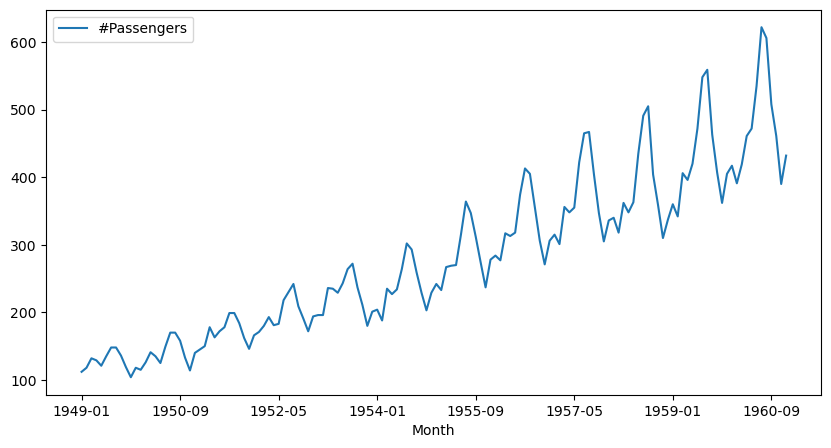

In [4]:
data.plot(figsize=(10,5))

In [5]:
scaler=MinMaxScaler()

In [6]:
data.shape

(144, 1)

In [7]:
train_data=data[:110]
test_data=data[110:]

In [8]:
scaled_train_data=scaler.fit_transform(train_data)
scaled_test_data=scaler.transform(test_data)

In [9]:
n_input=12   # how many previous word used to predict
n_features=1  # no of columns

In [10]:
generator = TimeseriesGenerator(scaled_train_data,scaled_train_data,length=n_input,batch_size=1)


#1 -> scaled data
#2 -> same used (sequence data)

In [12]:
x,y=generator[0]
print(x.flatten(),y)

[0.02203857 0.03856749 0.07713499 0.06887052 0.04683196 0.08539945
 0.12121212 0.12121212 0.08815427 0.04132231 0.         0.03856749] [[0.03030303]]


In [17]:
model=Sequential()
model.add(SimpleRNN(100,activation="relu",input_shape=(n_input,n_features)))
model.add(Dense(1,activation='tanh'))
model.compile(optimizer="adam",loss="mse")
hist=model.fit(generator,epochs=10)

Epoch 1/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0186
Epoch 2/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0088
Epoch 3/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0077
Epoch 4/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0053
Epoch 5/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0045
Epoch 6/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0041
Epoch 7/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0027
Epoch 8/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0029
Epoch 9/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0033
Epoch 10/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0031


In [23]:
model2=Sequential()
model2.add(LSTM(100,activation="relu",input_shape=(n_input,n_features)))
model2.add(Dense(1,activation='tanh'))
model2.compile(optimizer="adam",loss="mse")
model2.fit(generator,epochs=10)

Epoch 1/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0280
Epoch 2/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0140
Epoch 3/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0115
Epoch 4/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0104
Epoch 5/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0113
Epoch 6/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0122
Epoch 7/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0116
Epoch 8/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0099
Epoch 9/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0105
Epoch 10/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0068


In [22]:
model3=Sequential()
model3.add(Bidirectional(LSTM(100,activation="relu",input_shape=(n_input,n_features))))
model3.add(Dense(1))
model3.compile(optimizer="adam",loss="mse")
model3.fit(generator,epochs=10)

Epoch 1/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 0.0291
Epoch 2/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0147
Epoch 3/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0104
Epoch 4/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0117
Epoch 5/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0096
Epoch 6/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0091
Epoch 7/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0077
Epoch 8/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0067
Epoch 9/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0066
Epoch 10/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0051


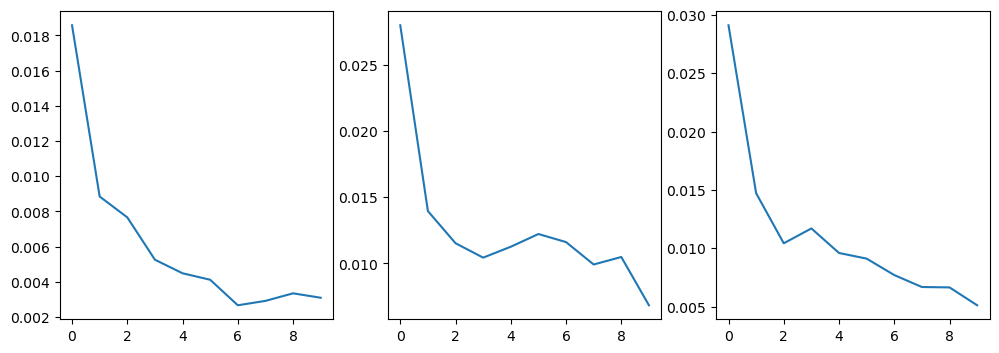

In [24]:
loss1=hist.history["loss"]
loss2=model2.history.history["loss"]
loss3=model3.history.history["loss"]

plt.figure(figsize=(12,4))
plt.subplot(131)
plt.plot(range(len(loss1)),loss1)
plt.subplot(132)
plt.plot(range(len(loss2)),loss2)
plt.subplot(133)
plt.plot(range(len(loss3)),loss3)

In [25]:
test_prediction1=[]
test_prediction2=[]
test_prediction3=[]

first_batch=scaled_train_data[-n_input:]
current_batch1=first_batch.reshape(1,n_input,n_features)
current_batch2=first_batch.reshape(1,n_input,n_features)
current_batch3=first_batch.reshape(1,n_input,n_features)
for i in range (len(test_data)):
    current_pred1=model1.predict(current_batch1)[0]
    current_pred2=model2.predict(current_batch1)[0]
    current_pred3=model3.predict(current_batch1)[0]
    test_prediction1. append(current_pred1)
    test_prediction2. append(current_pred2)
    test_prediction3. append(current_pred3)

current_batch1 = np.append(current_batch1[:,1:,:],[[current_pred1]],axis=1)
current_batch2 = np.append(current_batch2[:,1:,:],[[current_pred2]],axis=1)
current_batch3 = np.append(current_batch3[:,1:,:],[[current_pred3]], axis=1)

NameError: name 'model1' is not defined